# 06 — Final VentiMorph v2.8.1 architecture figure

Generates a publication-ready vector/raster architecture schematic for the frozen VentiMorph v2.8.1 model.

No MRI data, checkpoints, GPU, or Kaggle input is required.

In [1]:

from pathlib import Path
import hashlib
import io
import json
import os
import shutil
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")

print("Final presentation environment ready.")


Final presentation environment ready.


In [2]:

def find_zip_by_name(filename):
    hits = list(INPUT_ROOT.rglob(filename))
    if not hits:
        # Also support a Kaggle dataset that extracted an outer ZIP
        # but left the inner result ZIPs intact under a different path.
        hits = [p for p in INPUT_ROOT.rglob("*.zip") if p.name == filename]
    if len(hits) != 1:
        raise FileNotFoundError(
            f"Expected exactly one {filename!r} under /kaggle/input; found: {hits}"
        )
    return hits[0]


def read_member_bytes(zip_path, member_name):
    with zipfile.ZipFile(zip_path, "r") as zf:
        matches = [n for n in zf.namelist() if n.endswith(member_name)]
        if len(matches) != 1:
            raise FileNotFoundError(
                f"Expected exactly one *{member_name} inside {zip_path}; "
                f"found {matches}"
            )
        return zf.read(matches[0])


def read_member_image(zip_path, member_name):
    raw = read_member_bytes(zip_path, member_name)
    return Image.open(io.BytesIO(raw)).convert("RGB")


def extract_zip(zip_path, destination):
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(destination)
    return destination


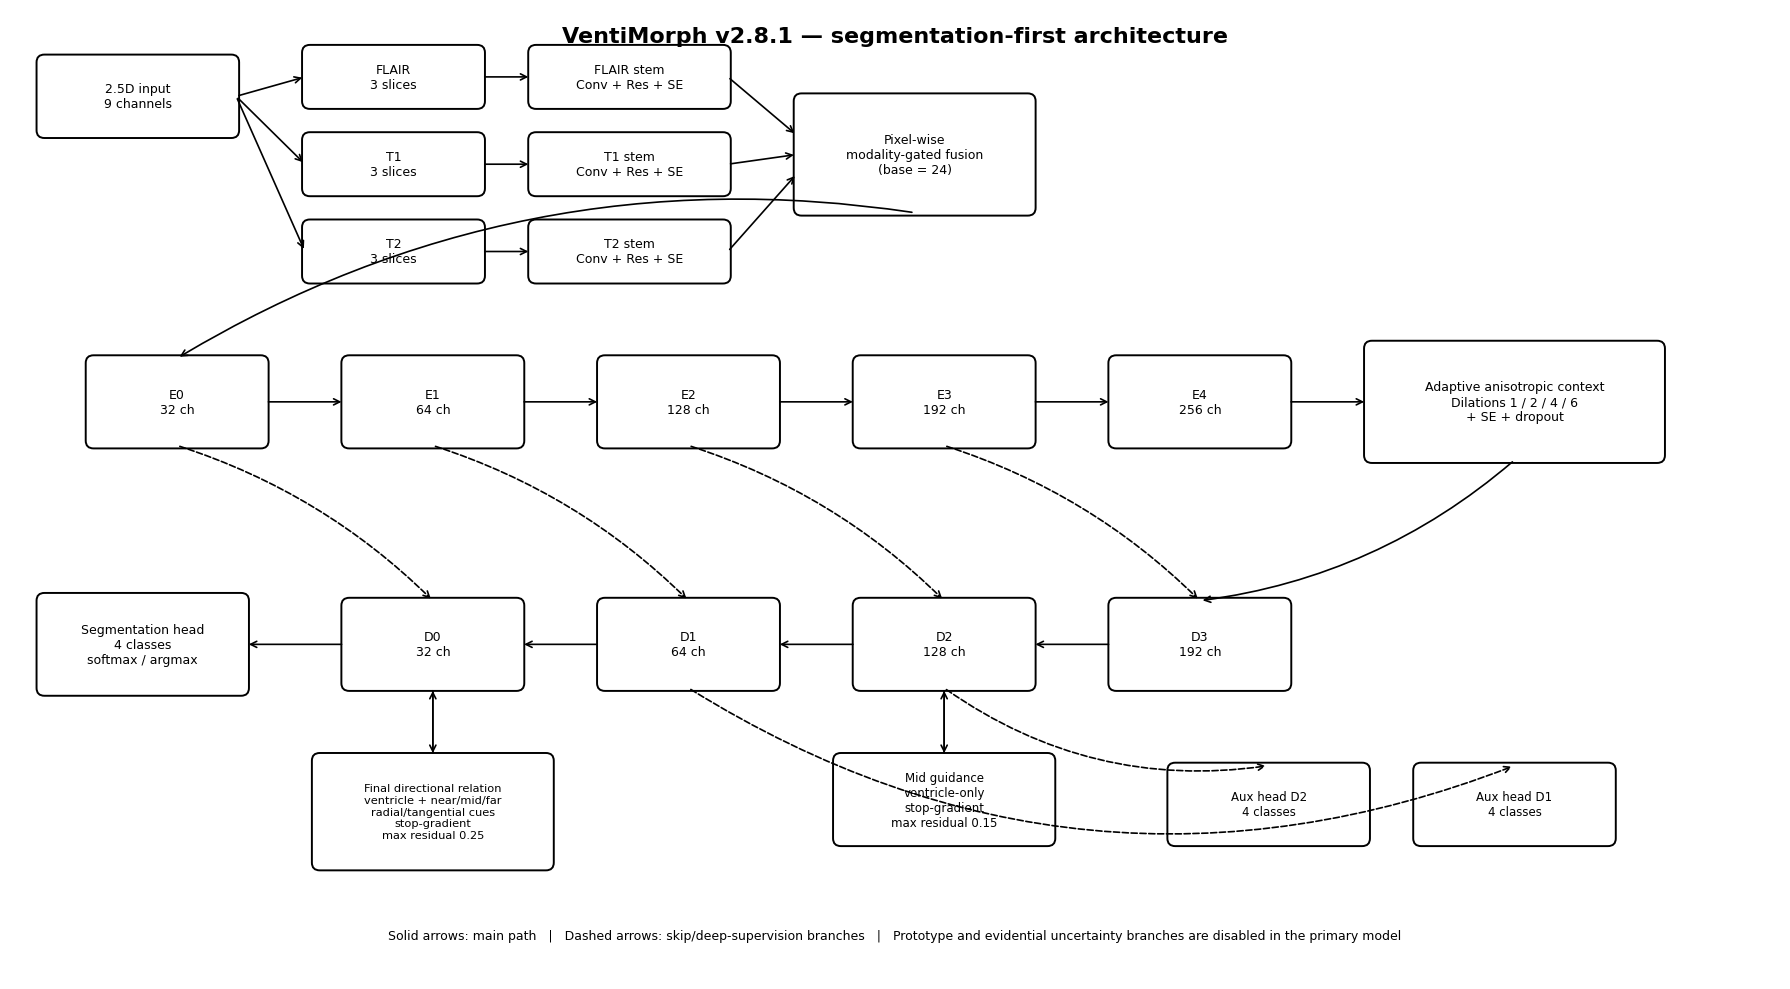

,Stage,Description,Channels_or_setting
0,Input,"FLAIR/T1/T2, 3 adjacent slices each",9 channels
1,Modality stems,Conv + residual + squeeze-excitation,24 channels each
2,Fusion,Pixel-wise learned modality gate,24 channels
3,Encoder,E0/E1/E2/E3/E4,32/64/128/192/256
4,Context,"Adaptive anisotropic dilations 1,2,4,6 + SE",256 channels
5,Decoder,D3/D2/D1/D0,192/128/64/32
6,Mid relation,"Ventricle-only, stop-gradient, bounded residual",max 0.15
7,Final relation,Directional near/mid/far + radial/tangential cues,max 0.25
8,Deep supervision,Auxiliary segmentation heads at D2 and D1,4 classes
9,Output,Full-resolution segmentation head,4 classes


In [3]:

from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

OUT = WORK_ROOT / "ventimorph_architecture_figure"
OUT.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(18, 10))
ax.set_xlim(0, 18)
ax.set_ylim(0, 10)
ax.axis("off")

def box(x, y, w, h, text, fontsize=9, linewidth=1.4, linestyle="-"):
    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.03,rounding_size=0.08",
        fill=False,
        linewidth=linewidth,
        linestyle=linestyle,
    )
    ax.add_patch(patch)
    ax.text(
        x + w/2, y + h/2, text,
        ha="center", va="center",
        fontsize=fontsize,
    )
    return patch

def arrow(x1, y1, x2, y2, linestyle="-", connectionstyle="arc3"):
    a = FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="->",
        mutation_scale=11,
        linewidth=1.2,
        linestyle=linestyle,
        connectionstyle=connectionstyle,
    )
    ax.add_patch(a)

# Input and modality-specific stems.
box(0.3, 8.7, 2.0, 0.8, "2.5D input\n9 channels")
box(3.0, 9.0, 1.8, 0.6, "FLAIR\n3 slices")
box(3.0, 8.1, 1.8, 0.6, "T1\n3 slices")
box(3.0, 7.2, 1.8, 0.6, "T2\n3 slices")

box(5.3, 9.0, 2.0, 0.6, "FLAIR stem\nConv + Res + SE")
box(5.3, 8.1, 2.0, 0.6, "T1 stem\nConv + Res + SE")
box(5.3, 7.2, 2.0, 0.6, "T2 stem\nConv + Res + SE")

box(8.0, 7.9, 2.4, 1.2, "Pixel-wise\nmodality-gated fusion\n(base = 24)")

arrow(2.3, 9.1, 3.0, 9.3)
arrow(2.3, 9.1, 3.0, 8.4)
arrow(2.3, 9.1, 3.0, 7.5)
arrow(4.8, 9.3, 5.3, 9.3)
arrow(4.8, 8.4, 5.3, 8.4)
arrow(4.8, 7.5, 5.3, 7.5)
arrow(7.3, 9.3, 8.0, 8.7)
arrow(7.3, 8.4, 8.0, 8.5)
arrow(7.3, 7.5, 8.0, 8.3)

# Encoder.
encoder_y = 5.5
enc = [
    (0.8, "E0\n32 ch"),
    (3.4, "E1\n64 ch"),
    (6.0, "E2\n128 ch"),
    (8.6, "E3\n192 ch"),
    (11.2, "E4\n256 ch"),
]
for x, label in enc:
    box(x, encoder_y, 1.8, 0.9, label)

arrow(9.2, 7.9, 1.7, 6.4, connectionstyle="arc3,rad=0.18")
for i in range(len(enc)-1):
    x1 = enc[i][0] + 1.8
    x2 = enc[i+1][0]
    arrow(x1, encoder_y+0.45, x2, encoder_y+0.45)

box(13.8, 5.35, 3.0, 1.2, "Adaptive anisotropic context\nDilations 1 / 2 / 4 / 6\n+ SE + dropout")
arrow(13.0, 5.95, 13.8, 5.95)

# Decoder.
decoder_y = 3.0
dec = [
    (11.2, "D3\n192 ch"),
    (8.6, "D2\n128 ch"),
    (6.0, "D1\n64 ch"),
    (3.4, "D0\n32 ch"),
]
for x, label in dec:
    box(x, decoder_y, 1.8, 0.9, label)

arrow(15.3, 5.35, 12.1, 3.9, connectionstyle="arc3,rad=-0.15")
for i in range(len(dec)-1):
    x1 = dec[i][0]
    x2 = dec[i+1][0] + 1.8
    arrow(x1, decoder_y+0.45, x2, decoder_y+0.45)

# Skip connections.
skip_pairs = [
    ((9.5, 5.5), (12.1, 3.9)),
    ((6.9, 5.5), (9.5, 3.9)),
    ((4.3, 5.5), (6.9, 3.9)),
    ((1.7, 5.5), (4.3, 3.9)),
]
for (x1, y1), (x2, y2) in skip_pairs:
    arrow(x1, y1, x2, y2, linestyle="--", connectionstyle="arc3,rad=-0.12")

# Relation-guidance modules.
box(8.4, 1.4, 2.2, 0.9, "Mid guidance\nventricle-only\nstop-gradient\nmax residual 0.15", fontsize=8.5)
arrow(9.5, 3.0, 9.5, 2.3)
arrow(9.5, 2.3, 9.5, 3.0)

box(3.1, 1.15, 2.4, 1.15, "Final directional relation\nventricle + near/mid/far\nradial/tangential cues\nstop-gradient\nmax residual 0.25", fontsize=8.2)
arrow(4.3, 3.0, 4.3, 2.3)
arrow(4.3, 2.3, 4.3, 3.0)

# Deep supervision and final output.
box(11.8, 1.4, 2.0, 0.8, "Aux head D2\n4 classes", fontsize=8.5)
box(14.3, 1.4, 2.0, 0.8, "Aux head D1\n4 classes", fontsize=8.5)
arrow(9.5, 3.0, 12.8, 2.2, linestyle="--", connectionstyle="arc3,rad=0.2")
arrow(6.9, 3.0, 15.3, 2.2, linestyle="--", connectionstyle="arc3,rad=0.25")

box(0.3, 2.95, 2.1, 1.0, "Segmentation head\n4 classes\nsoftmax / argmax")
arrow(3.4, 3.45, 2.4, 3.45)

ax.text(
    9.0, 9.82,
    "VentiMorph v2.8.1 — segmentation-first architecture",
    ha="center", va="top", fontsize=16, fontweight="bold",
)
ax.text(
    9.0, 0.45,
    "Solid arrows: main path   |   Dashed arrows: skip/deep-supervision branches   |   "
    "Prototype and evidential uncertainty branches are disabled in the primary model",
    ha="center", va="center", fontsize=9,
)

fig.tight_layout()
fig.savefig(OUT / "Figure_VentiMorph_v281_architecture.png", dpi=600, bbox_inches="tight")
fig.savefig(OUT / "Figure_VentiMorph_v281_architecture.pdf", bbox_inches="tight")
fig.savefig(OUT / "Figure_VentiMorph_v281_architecture.svg", bbox_inches="tight")
plt.show()

architecture_table = pd.DataFrame([
    ["Input", "FLAIR/T1/T2, 3 adjacent slices each", "9 channels"],
    ["Modality stems", "Conv + residual + squeeze-excitation", "24 channels each"],
    ["Fusion", "Pixel-wise learned modality gate", "24 channels"],
    ["Encoder", "E0/E1/E2/E3/E4", "32/64/128/192/256"],
    ["Context", "Adaptive anisotropic dilations 1,2,4,6 + SE", "256 channels"],
    ["Decoder", "D3/D2/D1/D0", "192/128/64/32"],
    ["Mid relation", "Ventricle-only, stop-gradient, bounded residual", "max 0.15"],
    ["Final relation", "Directional near/mid/far + radial/tangential cues", "max 0.25"],
    ["Deep supervision", "Auxiliary segmentation heads at D2 and D1", "4 classes"],
    ["Output", "Full-resolution segmentation head", "4 classes"],
], columns=["Stage", "Description", "Channels_or_setting"])

architecture_table.to_csv(
    OUT / "VentiMorph_v281_architecture_specification.csv",
    index=False,
)
display(architecture_table)


In [4]:

archive = shutil.make_archive(
    "/kaggle/working/MS3SEG_VENTIMORPH_ARCHITECTURE_FIGURE",
    "zip",
    root_dir=OUT,
)
print("Download:", archive)


Download: /kaggle/working/MS3SEG_VENTIMORPH_ARCHITECTURE_FIGURE.zip
